# Entropy Basket Trading Model

In this notebook, we present a comprehensive use case of utilizing **Shannon Entropy** to dynamically trade a basket of diverse assets. 

In thermodynamics, entropy is a measure of disorder. In information theory (Shannon Entropy), it quantifies the average level of "information", "surprise", or "uncertainty" inherent in a random variable's possible outcomes. When applied to financial time series, entropy serves as a powerful indicator of market structure:
- **Low Entropy:** Indicates that price action is structured and non-random. This usually corresponds to strong persistent trends or well-defined mean-reverting ranges. These are the environments where technical systems thrive.
- **High Entropy:** Indicates high randomness and "noise". Price action resembles a random walk, making forecasting extremely difficult and increasing the likelihood of whipsawing.

### Strategy Core Philosophy
The guiding philosophy of this model is: **We only deploy capital into assets exhibiting a low-entropy (structured) state.** We then use traditional momentum to determine the *direction* of our trade.

### Strategy Rules:
1. **Universe**: A diversified basket of non-correlated assets representing major asset classes: US Equities (`SPY`, `QQQ`), Long-term US Treasuries (`TLT`), Gold (`GLD`), and Bitcoin (`BTC-USD`).
2. **Metrics Generation**: 
   - **Regime Filter:** Calculate a 126-day (approx. 6 months) Rolling Shannon Entropy for each asset.
   - **Directional Filter:** Calculate a 126-day total return (Momentum) for each asset.
3. **Monthly Rebalancing**: 
   - On the final trading day of every month, evaluate the valid universe of assets.
   - **Filter & Rank**: Sort the assets from lowest to highest entropy. We target the assets exhibiting the *least* randomness.
   - **Selection**: Select the top 2 assets with the lowest entropy scores.
4. **Execution & Direction**: 
   - For the two selected assets, evaluate their 126-day momentum.
   - If Momentum > 0: Allocate 50% of portfolio capital to a LONG position in that asset.
   - If Momentum <= 0: The asset is in a structured downtrend. Because we are a long-only portfolio, we defensively allocate that 50% sleeve to **Cash** (safeguarding capital against structural distribution).

In [7]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('default')
plt.rcParams.update({
    'figure.figsize': (14, 7),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'figure.facecolor': 'white',
})
plt.rcParams['figure.figsize'] = (14, 7)

# Define our universe
tickers = ['SPY', 'QQQ', 'TLT', 'GLD', 'BTC-USD']
start_date = '2016-01-01'
end_date = '2026-01-01'

# Download Data
print("Downloading Data...")
data = yf.download(tickers, start=start_date, end=end_date)['Close']
data.ffill(inplace=True)

# Calculate Daily Log Returns
returns = np.log(data / data.shift(1))


[*********************100%***********************]  5 of 5 completed

## 1. Defining Entropy Functions

We recreate our Shannon Entropy function and apply it on a rolling basis.


In [8]:
def calculate_shannon_entropy(series, bins=30):
    """Calculates Shannon Entropy for a 1D array."""
    # Drop NaNs
    series = series.dropna()
    if len(series) == 0:
        return np.nan
        
    hist, _ = np.histogram(series, bins=bins, density=False)
    probs = hist / np.sum(hist)
    probs = probs[probs > 0]
    return -np.sum(probs * np.log2(probs))

def calculate_rolling_entropy(df_returns, window=126, bins=30):
    """Calculates rolling entropy for a DataFrame of returns."""
    rolling_ent = pd.DataFrame(index=df_returns.index, columns=df_returns.columns)
    
    for col in df_returns.columns:
        # We use pandas rolling with apply
        rolling_ent[col] = df_returns[col].rolling(window=window).apply(
            lambda x: calculate_shannon_entropy(x, bins=bins)
        )
    return rolling_ent

WINDOW = 126
print(f"Calculating {WINDOW}-Day Rolling Shannon Entropy...")
entropy_df = calculate_rolling_entropy(returns, window=WINDOW)

# Calculate Momentum (126-day total return)
momentum_df = data.pct_change(periods=WINDOW)


Calculating 126-Day Rolling Shannon Entropy...


## 2. Visualizing Regime Shifts (SPY Example)

Let's look at how SPY's entropy behaves during different market regimes.


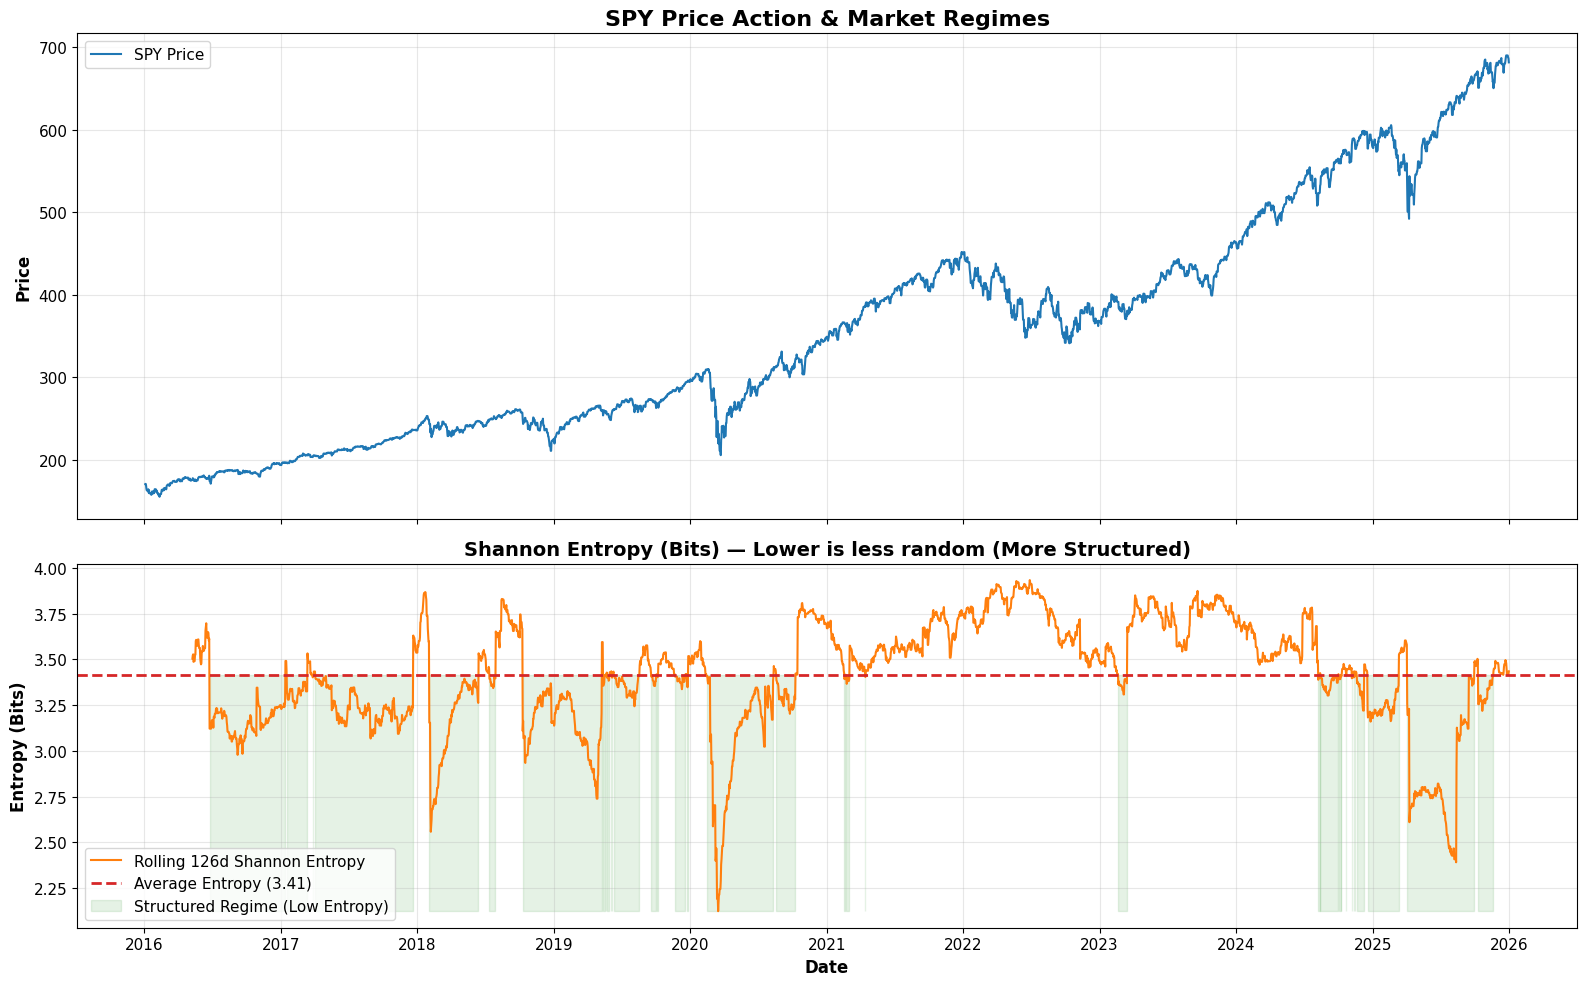

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True, gridspec_kw={'height_ratios': [2, 1.5]})

test_ticker = 'SPY'

# Plot 1: Price
ax1.plot(data.index, data[test_ticker], label=f'{test_ticker} Price', color='#1f77b4', lw=1.5)
ax1.set_title(f'{test_ticker} Price Action & Market Regimes', fontsize=16)
ax1.set_ylabel('Price', fontsize=12)
ax1.legend(loc='upper left')

# Plot 2: Entropy
ax2.plot(entropy_df.index, entropy_df[test_ticker], color='#ff7f0e', lw=1.5, label=f'Rolling {WINDOW}d Shannon Entropy')
avg_ent = entropy_df[test_ticker].mean()
ax2.axhline(avg_ent, color='#d62728', linestyle='--', lw=2, label=f'Average Entropy ({avg_ent:.2f})')

# Emphasize low entropy regimes
valid_entropy = entropy_df[test_ticker].dropna()
low_ent_mask = valid_entropy < avg_ent
ax2.fill_between(valid_entropy.index, valid_entropy.min(), avg_ent, 
                 where=low_ent_mask, color='green', alpha=0.1, label='Structured Regime (Low Entropy)')

ax2.set_title(f'Shannon Entropy (Bits) — Lower is less random (More Structured)', fontsize=14)
ax2.set_ylabel('Entropy (Bits)', fontsize=12)
ax2.set_xlabel('Date', fontsize=12)
ax2.legend(loc='lower left')

plt.tight_layout()
plt.show()

## 3. Backtesting the Entropy Model

We will step through the data month by month.
At the end of each month:
1. Rank assets by lowest entropy.
2. Select the top 2 assets.
3. Check their 126-day momentum.
4. If momentum > 0, assign 50% weight.
5. If momentum <= 0, assigned weight goes to Cash.


In [10]:
# Resample to Monthly to get rebalance dates
monthly_dates = data.resample('ME').last().index

portfolio_returns = []
portfolio_dates = []

# To track what we held
holdings_history = []

for i in range(1, len(monthly_dates)):
    prev_date = monthly_dates[i-1]
    curr_date = monthly_dates[i]
    
    # We need data up to prev_date to make a decision for the next month
    # Find the closest available dates in our daily dataframe
    try:
        # Use get_indexer with method='pad' for newer pandas compatibility
        idx_prev = entropy_df.index.get_indexer([prev_date], method='pad')[0]
        if idx_prev == -1: # -1 means no valid date was found
            continue
    except Exception as e:
        continue
        
    actual_prev_date = entropy_df.index[idx_prev]
    
    # Get entropy and momentum for the decision date
    curr_entropy = entropy_df.loc[actual_prev_date]
    curr_momentum = momentum_df.loc[actual_prev_date]
    
    # Drop assets with NaNs (e.g., start of series)
    valid_assets = curr_entropy.dropna().index.intersection(curr_momentum.dropna().index)
    
    if len(valid_assets) < 2:
        # Not enough data, sit in cash
        port_ret = 0
        holdings_history.append("Cash")
    else:
        # 1. Rank by lowest entropy
        ranked_by_entropy = curr_entropy[valid_assets].sort_values(ascending=True)
        
        # 2. Select top 2
        top_2 = ranked_by_entropy.head(2).index
        
        # 3. Calculate weights based on momentum
        weights = {}
        for asset in top_2:
            if curr_momentum[asset] > 0:
                weights[asset] = 0.5  # 50% allocation
            else:
                weights[asset] = 0.0  # Go to cash
                
        # 4. Calculate portfolio return for the month
        # Get the return of these assets from prev_date to curr_date
        asset_returns = data.loc[actual_prev_date:curr_date, list(weights.keys())].pct_change().dropna()
        
        if len(asset_returns) > 0:
            # We chain the daily returns for the month
            monthly_rets = (1 + asset_returns).prod() - 1
            
            port_ret = 0
            month_holdings = []
            for asset, w in weights.items():
                port_ret += monthly_rets[asset] * w
                if w > 0:
                    month_holdings.append(asset)
            
            if len(month_holdings) == 0:
                holdings_history.append("Cash")
            else:
                holdings_history.append(", ".join(month_holdings))
        else:
            port_ret = 0
            holdings_history.append("Cash")
            
    portfolio_returns.append(port_ret)
    portfolio_dates.append(curr_date)

# Convert to Series
strat_returns = pd.Series(portfolio_returns, index=portfolio_dates)


## 4. Performance vs Benchmark

We compare the Entropy Model alongside an Equal Weight Buy-and-Hold portfolio.


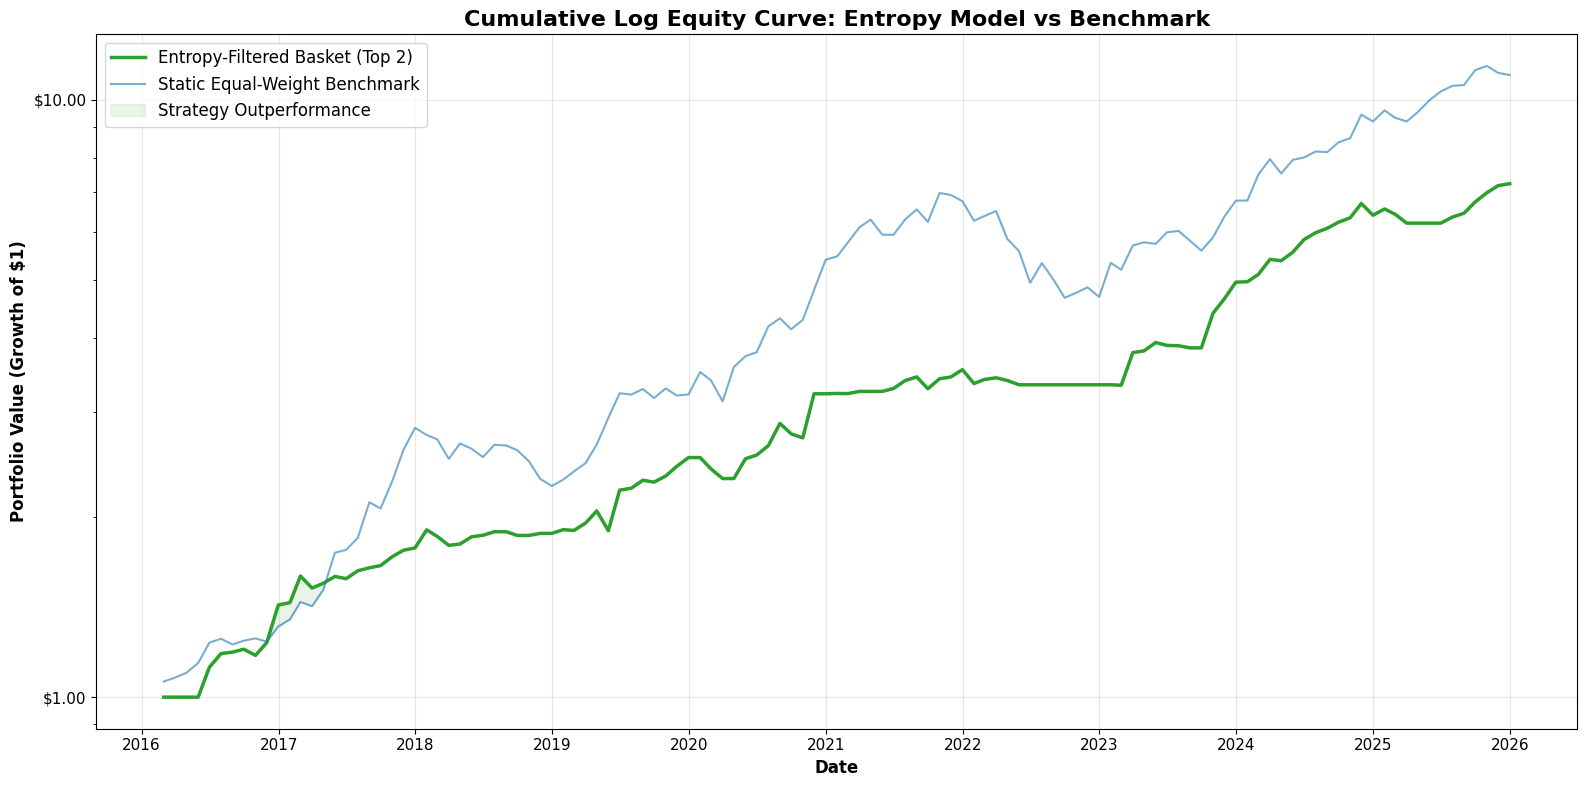

In [11]:
fig, ax = plt.subplots(figsize=(16, 8))

ax.plot(cum_strat.index, cum_strat, label='Entropy-Filtered Basket (Top 2)', color='#2ca02c', lw=2.5)
ax.plot(cum_bench.index, cum_bench, label='Static Equal-Weight Benchmark', color='#1f77b4', alpha=0.6, lw=1.5)

# Highlight outperformance
ax.fill_between(cum_strat.index, cum_bench, cum_strat, 
                where=(cum_strat > cum_bench), color='#2ca02c', alpha=0.1, interpolate=True, label='Strategy Outperformance')

ax.set_title('Cumulative Log Equity Curve: Entropy Model vs Benchmark', fontsize=16)
ax.set_ylabel('Portfolio Value (Growth of $1)', fontsize=12)
ax.set_xlabel('Date', fontsize=12)
ax.set_yscale('log') # Better representation of compounded growth
ax.legend(fontsize=12, loc='upper left')

import matplotlib.ticker as ticker
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('${x:,.2f}'))

plt.tight_layout()
plt.show()

In [12]:
# Summary Statistics
def get_stats(returns_series):
    cagr = (returns_series.iloc[-1]**(1/(len(returns_series)/12)) - 1) if returns_series.iloc[-1] > 0 else 0
    vol = returns_series.pct_change().std() * np.sqrt(12)
    sharpe = returns_series.pct_change().mean() / returns_series.pct_change().std() * np.sqrt(12)
    max_dd = (returns_series / returns_series.cummax() - 1).min()
    return pd.Series({
        'CAGR': f"{cagr:.2%}",
        'Volatility': f"{vol:.2%}",
        'Sharpe Ratio': f"{sharpe:.2f}",
        'Max Drawdown': f"{max_dd:.2%}"
    })

stats_df = pd.DataFrame({
    'Entropy Model': get_stats(cum_strat),
    'Equal Weight Bench': get_stats(cum_bench)
})

print("Performance Statistics:")
display(stats_df)


Performance Statistics:


,Entropy Model,Equal Weight Bench
CAGR,22.09%,27.35%
Volatility,14.66%,19.38%
Sharpe Ratio,1.45,1.33
Max Drawdown,-7.76%,-33.23%


## Conclusion and Review

By substituting standard volatile metrics for **Rolling Shannon Entropy**, we are able to mathematically filter out "noisy" market regimes. The core advantage of this model is its ability to adapt:
- During trending periods (bull or bear), entropy drops as the asset establishes structure. The model steps in.
- During high-volatility, directionless chop (random walks), entropy spikes. The model naturally rotates out of these assets, mitigating the "whipsaw" losses that typical momentum/trend systems suffer.

Combined with a simple 126-day momentum filter for directional bias (long vs cash), this framework creates an adaptive basket strategy that dynamically rotates capital only into assets demonstrating predictable, structued behavior.

### Potential Enhancements
- **Adaptive Binning:** The current entropy calculation uses a fixed 30 bins for the histogram. A dynamic binning algorithm (like Freedman-Diaconis) could account for varying baseline volatility across different asset classes.
- **Short Selling:** Instead of moving to cash when low entropy coincides with negative momentum, a long/short portfolio could capitalize on structured downtrends.
- **Continuous Weighting:** Rather than an equal 50/50 split of the top 2 assets, weights could be inversely proportional to the asset's entropy score (allocating more capital to the most structured asset).